<a href="https://colab.research.google.com/github/BrahiamG1/Arquitectura-Avanzada-de-Computadores-/blob/main/Microarchitecture_Simulation_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Microarchitecture Simulation Assignment

**Realizado por:**

BRAHIAM GOMEZ MURILLO

CRISTIAN IBARRA HERNANDEZ

*Estudiantes de Ing. Electronica de la Universidad de Antioquia*

# Link repositorio:
https://github.com/BrahiamG1/Arquitectura-Avanzada-de-Computadores-/blob/main/Microarchitecture_Simulation_Assignment.ipynb

# Link Resultados (Drive):
https://drive.google.com/drive/folders/1CVG2l_kHjwYacb4eSlNl-fLvB9k1p-DJ?usp=sharing

# Scripts de automatizacion (Ubuntu)
## 1000 simulaciones:


In [ ]:
#!/usr/bin/env python3
import subprocess
import itertools
import random
from concurrent.futures import ProcessPoolExecutor


# Función que ejecuta una simulación individual
def ejecutar_simulacion(datos):
    ciclo, params = datos
    l1i, l1d, iq, lq, sq, alu, fp_simd, cmp = params

    outdir = f"m5out_mp3_ciclo{ciclo}l1i{l1i}l1d{l1d}iq{iq}lq{lq}sq{sq}alu{alu}fp{fp_simd}cmp{cmp}"

    command = [
        './build/ARM/gem5.fast',
        f'--outdir={outdir}',
        'scripts/CortexA76_scripts_gem5/CortexA76.py',
        '-c', 'workloads/mp3_enc/mp3_enc',
        '-o', f'workloads/mp3_enc/mp3enc_testfile.wav {outdir}/output.mp3',
        f'--l1i_size={l1i}',
        f'--l1d_size={l1d}',
        f'--iq_entries={iq}',
        f'--lq_entries={lq}',
        f'--sq_entries={sq}',
        f'--num_fu_intALU={alu}',
        f'--num_fu_FP_SIMD_ALU={fp_simd}',
        f'--num_fu_cmp={cmp}'
    ]

    print(f"[INICIANDO CICLO {ciclo}/1000] --- alu={alu}, cmp={cmp}, fp={fp_simd}, l1i={l1i}, l1d={l1d}, iq={iq}, lq={lq}, sq={sq}")

    try:
        subprocess.run(command, check=True, capture_output=True, text=True)
        return f"Simulación [Ciclo {ciclo}/1000] finalizada con exito."
    except subprocess.CalledProcessError as e:
        return f"Error durante la simulación [Ciclo {ciclo}/1000]. Código: {e.returncode}"



if __name__ == '__main__':
    l1i_sizes          = ['32kB', '64kB']
    l1d_sizes          = ['32kB', '64kB']
    iq_entries         = [16, 32, 64]
    lq_entries         = [40, 70, 90]
    sq_entries         = [40, 70, 90]
    num_fu_intALU      = [2, 3, 4, 5]
    num_fu_FP_SIMD_ALU = [2, 3, 4]
    num_fu_cmp         = [1, 2]


    todas_combinaciones = list(itertools.product(
        l1i_sizes, l1d_sizes, iq_entries, lq_entries, sq_entries,
        num_fu_intALU, num_fu_FP_SIMD_ALU, num_fu_cmp
    ))


    random.seed(42)
    combinaciones = random.sample(todas_combinaciones, 1000)

    datos_simulacion = [(ciclo, params) for ciclo, params in enumerate(combinaciones, start=1)]


    print(f"Iniciando automatización: {len(combinaciones)} iteraciones (6 en PARALELO).\n")


    # n núcleos
    with ProcessPoolExecutor(max_workers=6) as executor:
        for resultado in executor.map(ejecutar_simulacion, datos_simulacion):
            print(resultado)

## McPAT:

In [ ]:
import os
import subprocess
from multiprocessing import Pool, cpu_count

SCRIPT_CONVERSOR = os.path.abspath("gem5toMcPAT_cortexA76.py")
PLANTILLA_XML = os.path.abspath("ARM_A76_2.1GHz.xml")
MCPAT_PATH = os.path.abspath("../../mcpat/mcpat")

directorio_gem5 = os.path.abspath("../../")

def procesar_una_carpeta(datos):
    """Función que procesa una sola carpeta y muestra su estado en tiempo real"""
    indice, total, elemento = datos
    ruta_carpeta = os.path.join(directorio_gem5, elemento)

    archivo_stats = os.path.join(ruta_carpeta, "stats.txt")
    archivo_json = os.path.join(ruta_carpeta, "config.json")
    archivo_config = os.path.join(ruta_carpeta, "config.xml")
    ruta_log = os.path.join(ruta_carpeta, "config_.log")


    # Verificar que existan los archivos
    if not (os.path.isfile(archivo_stats) and os.path.isfile(archivo_json)):
        print(f"[{indice}/{total}] Faltan archivos en: {elemento}", flush=True)
        return


    # Aviso de en qué carpeta va
    print(f"[{indice}/{total}] ---> Procesando carpeta: {elemento}", flush=True)


    try:
        comando_xml = [
            "python3",
            SCRIPT_CONVERSOR,
            "stats.txt",
            "config.json",
            PLANTILLA_XML
        ]
        subprocess.run(
            comando_xml,
            cwd=ruta_carpeta,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL,
            check=True
        )


        if os.path.isfile(archivo_config):
            comando_mcpat = [MCPAT_PATH, "-infile", "config.xml", "-print_level", "1"]

            with open(ruta_log, "w") as log_file:
                subprocess.run(
                    comando_mcpat,
                    cwd=ruta_carpeta,
                    stdout=log_file,
                    stderr=subprocess.STDOUT,
                    check=True
                )

            # Aviso de cuando termina el proceso en dicha carpeta
            print(f"[{indice}/{total}] TERMINADO: Proceso finalizado en: {elemento}", flush=True)


    except Exception as e:
        print(f"[{indice}/{total}] [ERROR] Falló en {elemento}: {e}", flush=True)

if __name__ == "__main__":
    print(f"Buscando simulaciones en: {directorio_gem5}\n")
    nombres_carpetas = []
    for elemento in os.listdir(directorio_gem5):
        ruta_carpeta = os.path.join(directorio_gem5, elemento)
        if os.path.isdir(ruta_carpeta) and elemento.startswith("m5out_mp3_ciclo"):
            nombres_carpetas.append(elemento)


    # Ordenar alfabéticamente
    nombres_carpetas.sort()

    total_simulaciones = len(nombres_carpetas)
    nucleos_disponibles = cpu_count()

    carpetas_a_procesar = []
    for i, nombre in enumerate(nombres_carpetas, start=1):
        carpetas_a_procesar.append((i, total_simulaciones, nombre))


    print(f"Se encontraron {total_simulaciones} carpetas de simulación.")
    print(f"Usando 10 de {nucleos_disponibles} núcleos disponibles.\n")
    print("-" * 60)

    with Pool(processes=10) as pool:
        pool.map(procesar_una_carpeta, carpetas_a_procesar)


    print("-" * 60)
    print("\n¡¡¡Proceso completado para todas las carpetas!!!")

# The instruction-class profiling:
El perfil de clases de instrucciones del "mp3_enc" muestra que las operaciones de lectura y escritura de memoria representan el 55,63 % de las instrucciones realizadas, mientras que la clase IntAlu constituye el 34,57 %. El resto se divide en el uso de la ALU FP.

Por otro lado, la variable statFuBusy muestra que las operaciones de MemRead y MemWrite representan en conjunto, aproximadamente, el 84,38 % de los intentos  de utilizar unidades funcionales sin que hubiera una disponible.

Finalmente, la cache de instrucciones L1 tiene un miss rate de 0.000525, es decir, del 0.05%.   La caché de datos L1 también es altamente eficiente, con una tasa de fallos de 0.001122 (0.11%).

# Design space exploration (DSE)
Debido a que el objetivo es aumentar el IPC, se tomaron las siguientes decisiones:

*   Como se presenta una gran dependencia de las operaciones de lectura y escritura en memoria, se decidio aumentar las colas del procesador:
    *   **lq_entries** y **sq_entries**: Si modificar las capacidades de las colas de carga y almacenamiento cambia el rendimiento y la energía calculada.
    *   **iq_entries**: Si la cantidad de entradas disponibles limita el aprovechamiento del paralelismo entre instrucciones (ILP), esto debido a la dependiencia entre instrucciones.

*   Aumentar la cantidad de **ALUs de enteros, punto flotante y CMP** (comparacion de punto flotante), esto debido a la cantidad de intentos de usos sin que estuvieran disponibles.



*   Disminuir el tamaño de la **cache de datos e instrucciones** para ver si afectan el IPC y el consumo energetico.


Al realizar unas pocas simulaciones, se noto una mejora en el IPC. Por lo cual, se decidio el siguiente DSE:



| Categoría | Parámetro | Valores |
| :--- | :--- | :--- |
| **Caché** | `l1i_kB` (Instrucciones) | `[32, 64]` |
| | `l1d_kB` (Datos) | `[32, 64]` |
| **Colas** | `iq_entries` (Instruction Queue) | `[16, 32, 64]` |
| | `lq_entries` (Load Queue) | `[40, 70, 90]` |
| | `sq_entries` (Store Queue) | `[40, 70, 90]` |
| **Unidades** | `num_alu` (Enteros) | `[2, 3, 4, 5]` |
| | `num_fp` (Punto Flotante) | `[2, 3, 4]` |
| | `num_cmp` (Comparadores) | `[1, 2]` |






In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import numpy as np

In [140]:

print("Selecciona el archivo:")
subido = files.upload()

nombre_archivo = list(subido.keys())[0]
df = pd.read_csv(nombre_archivo)

# Asegurar que esté ordenado del ciclo 1 al 1000
df = df.sort_values(by="ciclo").reset_index(drop=True)

print(f"\nTotal de simulaciones cargadas: {len(df)}")
df.head()

Selecciona el archivo:


Saving resultados_completos.csv to resultados_completos.csv

Total de simulaciones cargadas: 1000


,id_configuracion,ciclo,l1i_kB,l1d_kB,iq_entries,lq_entries,sq_entries,num_alu,num_fp,num_cmp,...,cpi,ipc,area_mm2,peak_power_W,total_leakage_W,peak_dynamic_W,runtime_dynamic_W,potencia_total_W,energia_formula,EDP_formula
0,m5out_mp3_ciclo1l1i32kBl1d32kBiq64lq40sq70alu2...,1,32,32,64,40,70,2,2,1,...,0.851658,1.174180,35.3799,41.5577,0.536168,41.0216,1.94521,2.481378,2.113285,1.799796
1,m5out_mp3_ciclo2l1i32kBl1d32kBiq16lq70sq70alu3...,2,32,32,16,70,70,3,2,1,...,1.047209,0.954919,35.3830,41.3855,0.536260,40.8492,1.61051,2.146770,2.248117,2.354248
2,m5out_mp3_ciclo3l1i32kBl1d64kBiq64lq40sq70alu5...,3,32,64,64,40,70,5,4,1,...,0.850398,1.175921,35.4545,41.5941,0.538697,41.0554,1.95840,2.497097,2.123526,1.805843
3,m5out_mp3_ciclo4l1i32kBl1d64kBiq32lq70sq90alu5...,4,32,64,32,70,90,5,2,2,...,0.864184,1.157161,35.4620,41.4753,0.538916,40.9364,1.91854,2.457456,2.123694,1.835263
4,m5out_mp3_ciclo5l1i32kBl1d64kBiq32lq40sq90alu2...,5,32,64,32,40,90,2,3,1,...,0.864615,1.156584,35.4557,41.4621,0.538727,40.9233,1.91336,2.452087,2.120111,1.833080


## Aplicacion del algoritmo Greedy: Búsqueda Local Estricta

1. Se hallan todas las posibles configuraciones, de acuerdo a la cantidad de parametros utilizados y el rango de cada uno. En este caso, son 14 configuraciones.

In [141]:
# Space exploration (DSE)
VALORES = {
    "l1i_kB"    :     [32, 64],
    "l1d_kB"    :     [32, 64],
    "iq_entries": [16, 32, 64],
    "lq_entries": [40, 70, 90],
    "sq_entries": [40, 70, 90],
    "num_alu"   : [2, 3, 4, 5],
    "num_fp"    :    [2, 3, 4],
    "num_cmp"   :       [1, 2]
}

PARAMETROS = list(VALORES.keys())

def generar_vecinos_extendidos(actual):
    """Genera todas las configuraciones vecinas posibles cambiando
    un parámetro a la vez"""
    vecinos = []

    # Recorro los parametros modificados
    for variable in PARAMETROS:
        valores = VALORES[variable]

        for valor in valores:
            if valor != actual[variable]:
                nueva_config = actual.copy()
                nueva_config[variable] = valor
                vecinos.append(nueva_config)

    return vecinos

2. Se valida que las configuraciones generadas se simularon o se encuentran en el CSV

In [142]:
def buscar_en_csv(df, config_dict):

    """Devuelve la fila del CSV que coincide con los 8 parámetros del diccionario"""
    condicion = (
        (df["l1i_kB"]     == config_dict["l1i_kB"]) &
        (df["l1d_kB"]     == config_dict["l1d_kB"]) &
        (df["iq_entries"] == config_dict["iq_entries"]) &
        (df["lq_entries"] == config_dict["lq_entries"]) &
        (df["sq_entries"] == config_dict["sq_entries"]) &
        (df["num_alu"]    == config_dict["num_alu"]) &
        (df["num_fp"]     == config_dict["num_fp"]) &
        (df["num_cmp"]    == config_dict["num_cmp"])
    )
    resultado = df[condicion]

    if not resultado.empty:
        return resultado.iloc[0]  # Retorna la fila encontrada
    return None                   # No se simuló esa combinación

2. En vez de hacer una busqueda en las 2592 combinaciones *(2 * 2 * 3 * 3 * 3 * 4 * 3 * 2)*, se genera una busqueda optima explorando en menos del 5 % del espacio original.

In [143]:
def ejecutar_greedy(df, metrica="EDP_formula"):

    """Encontrar la mejor configuración posible
    de parámetros para minimizar una métrica"""

    # Empezar con la primera configuración del CSV
    actual = df.iloc[0].copy()

    # Guardar los parámetros de la configuración actual
    configuracion = {}

    for parametro in PARAMETROS:
        configuracion[parametro] = int(actual[parametro])

    camino = [actual.copy()]
    paso = 0

    while True:

        # Generar los vecinos de la configuración actual
        vecinos = generar_vecinos_extendidos(configuracion)

        # Buscar los vecinos que existen en el CSV
        resultados = []

        for vecino in vecinos:
            resultado = buscar_en_csv(df, vecino)

            if resultado is not None:
                resultados.append(resultado)

        # Si no hay vecinos disponibles, terminar
        if len(resultados) == 0:
            break

        # vecino con menor EDP
        mejor_vecino = resultados[0]

        for vecino in resultados:
            if vecino[metrica] < mejor_vecino[metrica]:
                mejor_vecino = vecino

        # Si no mejora el EDP actual, terminar
        if mejor_vecino[metrica] >= actual[metrica]:
            break

        # Avanzar hacia el mejor vecino
        actual = mejor_vecino.copy()

        # Actualizar los parámetros de la nueva configuración
        for parametro in PARAMETROS:
            configuracion[parametro] = int(actual[parametro])

        # Guardar la mejora encontrada
        camino.append(actual.copy())
        paso += 1

    return actual, pd.DataFrame(camino), paso

In [152]:
mejor_greedy, df_camino, pasos = ejecutar_greedy(df, metrica="EDP_formula")
print(f"cantida de ejecuciones: {pasos}")
print(f"mejor configuracion con Greedy: {mejor_greedy}")

cantida de ejecuciones: 2
mejor configuracion con Greedy: id_configuracion     m5out_mp3_ciclo583l1i32kBl1d32kBiq64lq40sq40al...
ciclo                                                              583
l1i_kB                                                              32
l1d_kB                                                              32
iq_entries                                                          64
lq_entries                                                          40
sq_entries                                                          40
num_alu                                                              2
num_fp                                                               2
num_cmp                                                              2
simSeconds                                                    0.096649
hostSeconds                                                     562.97
simInsts                                                   238343896.0
numCycles          

In [145]:
# Mejor Rendimiento
mejor_rendimiento = df.loc[df["cpi"].idxmin()]

# Menor consumo
mejor_energia = df.loc[df["energia_formula"].idxmin()]

# Mejor EDP
mejor_edp = df.loc[df["EDP_formula"].idxmin()]

# tabla comparativa
tabla_mejores = pd.DataFrame([
    mejor_rendimiento,
    mejor_energia,
    mejor_edp
])

tabla_mejores.insert(0, "Criterio Ganador", [
    "Mejor Rendimiento (Menor CPI)",
    "Menor Energía",
    "Mejor Balance (Menor EDP)"
])

columnas_mostrar = [
    "Criterio Ganador", "ciclo", "id_configuracion",
    "l1i_kB", "l1d_kB", "iq_entries", "lq_entries", "sq_entries",
    "num_alu", "num_fp", "num_cmp",
    "cpi", "potencia_total_W",
    "energia_formula", "EDP_formula"
]

tabla_mejores[columnas_mostrar]

,Criterio Ganador,ciclo,id_configuracion,l1i_kB,l1d_kB,iq_entries,lq_entries,sq_entries,num_alu,num_fp,num_cmp,cpi,potencia_total_W,energia_formula,EDP_formula
329,Mejor Rendimiento (Menor CPI),330,m5out_mp3_ciclo330l1i64kBl1d64kBiq64lq90sq70al...,64,64,64,90,70,2,4,2,0.846521,2.522602,2.135436,1.807691
929,Menor Energía,930,m5out_mp3_ciclo930l1i32kBl1d32kBiq32lq40sq40al...,32,32,32,40,40,5,2,2,0.864968,2.418855,2.092232,1.809714
847,Mejor Balance (Menor EDP),848,m5out_mp3_ciclo848l1i32kBl1d32kBiq64lq70sq40al...,32,32,64,70,40,4,2,2,0.847950,2.484448,2.106688,1.786366


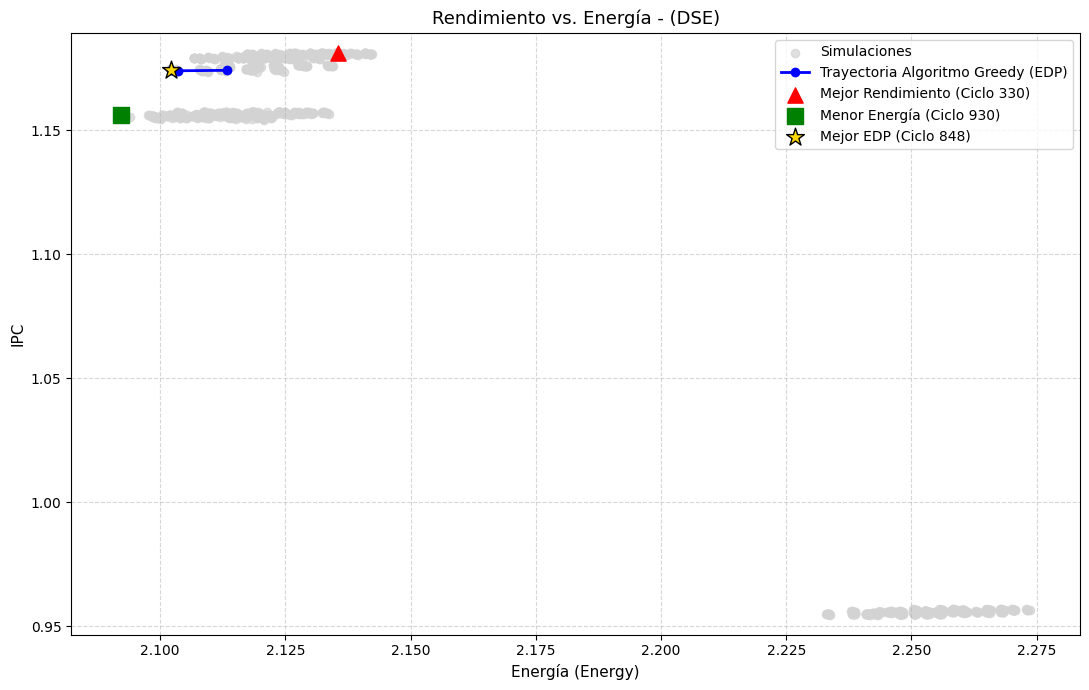

In [146]:
plt.figure(figsize=(11, 7))

# Todos los puntos de simulación
plt.scatter(
    df["energia_formula"],
    df["ipc"],
    color="lightgray",
    alpha=0.7,
    label="Simulaciones"
)

# Ruta seguida por el algoritmo Greedy
plt.plot(
    df_camino["energia_formula"],
    df_camino["ipc"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Trayectoria Algoritmo Greedy (EDP)"
)

# Destacar las 3 mejores configuraciones encontradas
plt.scatter(
    mejor_rendimiento["energia_formula"],
    mejor_rendimiento["ipc"],
    color="red",
    s=120,
    marker="^",
    zorder=5,
    label=f"Mejor Rendimiento (Ciclo {int(mejor_rendimiento['ciclo'])})"
)

plt.scatter(
    mejor_energia["energia_formula"],
    mejor_energia["ipc"],
    color="green",
    s=120,
    marker="s",
    zorder=5,
    label=f"Menor Energía (Ciclo {int(mejor_energia['ciclo'])})"
)

plt.scatter(
    mejor_greedy["energia_formula"],
    mejor_greedy["ipc"],
    color="gold",
    edgecolors="black",
    s=180,
    marker="*",
    zorder=6,
    label=f"Mejor EDP (Ciclo {int(mejor_edp['ciclo'])})"
)

# Configuración de etiquetas, títulos y formato
plt.title("Rendimiento vs. Energía - (DSE)", fontsize=13)
plt.xlabel("Energía (Energy)", fontsize=11)
plt.ylabel("IPC", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

margen_x = 0.010
plt.xlim(
    df["energia_formula"].min() - margen_x,
    df["energia_formula"].max() + margen_x
)

margen_y = 0.008
plt.ylim(
    df["ipc"].min() - margen_y,
    df["ipc"].max() + margen_y
)

plt.show()




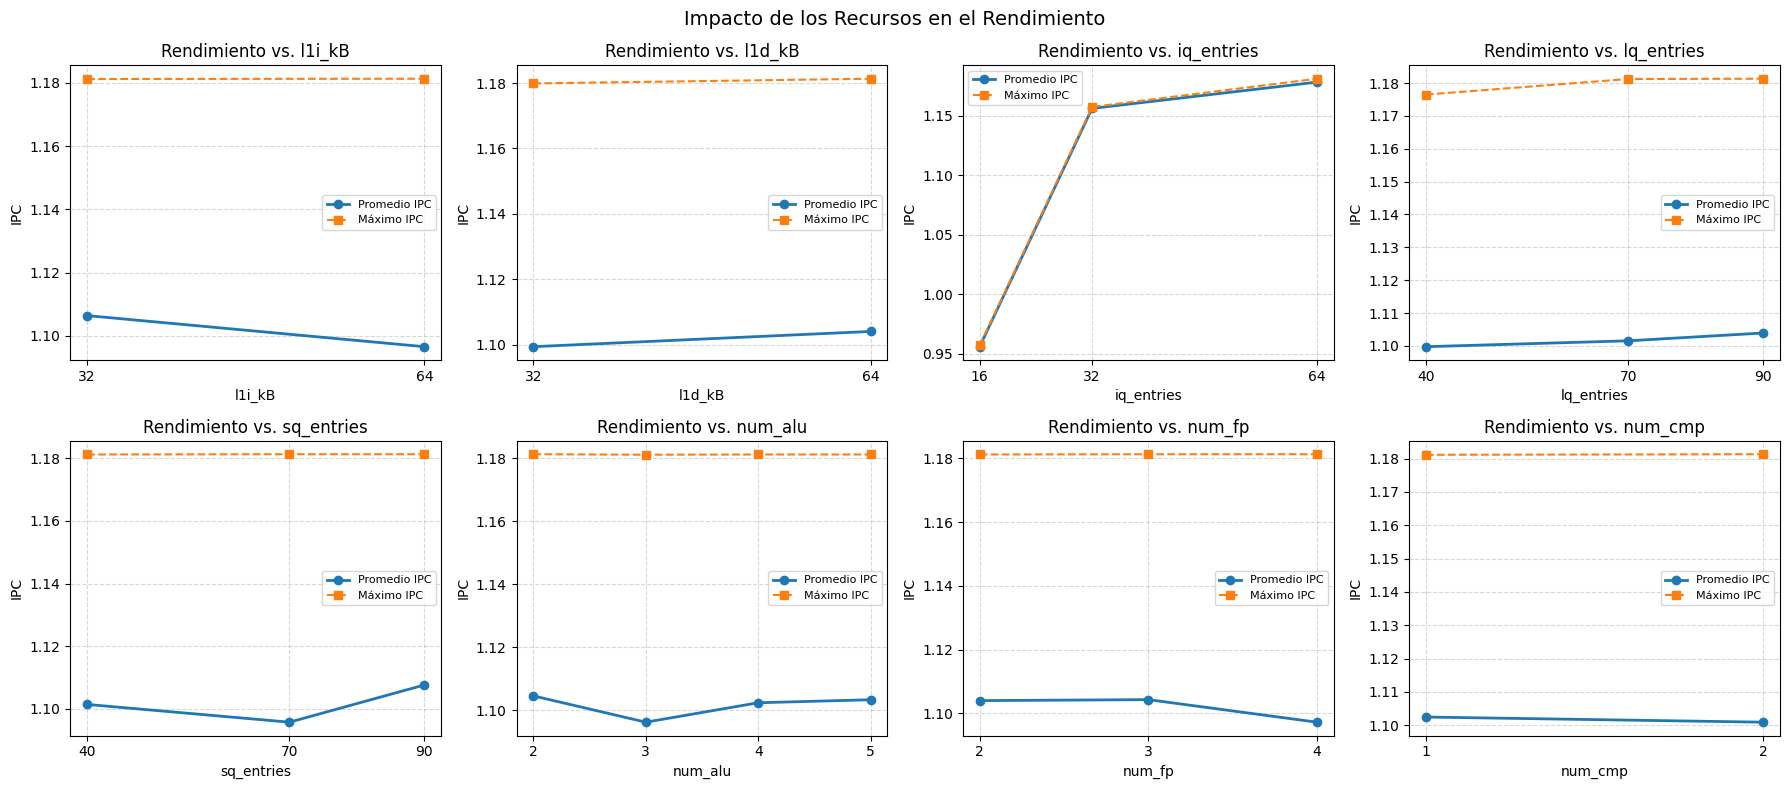

In [147]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, param in enumerate(PARAMETROS):
    # Agrupar por el recurso y calcular el rendimiento promedio y máximo en cada tamaño
    resumen = df.groupby(param)["ipc"].agg(["mean", "max"]).reset_index()

    ax = axes[i]
    ax.plot(resumen[param], resumen["mean"], marker="o", linewidth=2, label="Promedio IPC")
    ax.plot(resumen[param], resumen["max"], marker="s", linestyle="--", label="Máximo IPC")

    ax.set_title(f"Rendimiento vs. {param}")
    ax.set_xlabel(param)
    ax.set_ylabel("IPC")
    ax.set_xticks(resumen[param])
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(fontsize=8)

plt.suptitle("Impacto de los Recursos en el Rendimiento", fontsize=14)
plt.tight_layout()
plt.show()

In [148]:
# Tiempos registrados en stats.txt (hostSeconds)
tiempo_promedio_gem5_s = df["hostSeconds"].mean()
tiempo_total_cpu_gem5_h = df["hostSeconds"].sum() / 3600

nucleos_usados = 6
tiempo_real_gem5_h = tiempo_total_cpu_gem5_h / nucleos_usados

# Tiempos estimados/medidos de McPAT
tiempo_una_sim_mcpat_s = 60 # este dato se saco al tomar 20 archivos de config.log,y observar la hora de creacion y la hora en que se modificaba.
tiempo_total_mcpat_min = (tiempo_una_sim_mcpat_s * len(df) / nucleos_usados) / 3600

print("=== Tiempos de simulacion ===")
print(f"Total de simulaciones en el DSE:           {len(df)}")
print(f"Tiempo promedio de 1 simulación en Gem5:   {tiempo_promedio_gem5_s:.2f} segundos")
print(f"Tiempo total de CPU acumulado en Gem5:     {tiempo_total_cpu_gem5_h:.2f} horas")
print(f"Tiempo real en paralelo Gem5 ({nucleos_usados} hilos):   {tiempo_real_gem5_h:.2f} horas")
print("-" * 50)
print(f"Tiempo promedio de 1 simulación en McPAT:  ~{tiempo_una_sim_mcpat_s:.2f} segundos")
print(f"Tiempo total en paralelo McPAT ({nucleos_usados} hilos): ~{tiempo_total_mcpat_min:.2f} horas")

=== Tiempos de simulacion ===
Total de simulaciones en el DSE:           1000
Tiempo promedio de 1 simulación en Gem5:   569.29 segundos
Tiempo total de CPU acumulado en Gem5:     158.14 horas
Tiempo real en paralelo Gem5 (6 hilos):   26.36 horas
--------------------------------------------------
Tiempo promedio de 1 simulación en McPAT:  ~60.00 segundos
Tiempo total en paralelo McPAT (6 hilos): ~2.78 horas


Conclusiones



*   Aunque la Cache es la segunda memoria mas rapida,  no se observa un aumento considerable en el IPC al incrementar su tamaño. Esto debido al tipo de instrucciones que se utilizan en el **mp3_enc**
*   Se nota que hay una gran dependencia entre las instrucciones, esto debido a que al aumentar la cantidad de Cola de Instrucciones, se mejora drasticamente el IPC. Esto debido a que se permite que se almacenen mayor cantidad de instrucciones, por lo cual, se incrementa la probabilidad de encontrar instrucciones independientes que sí se pueden ejecutar en paralelo


*   La mayoria de instrucciones eran de escritura y lectura de la memoria, pero despues de realizar las simulaciones en conjunto y al analizar sus datos, se puede observar que el problema era debido al aprovechamiento del ILP y no de la cantidad de instrucciones de este tipo, y no tanto del espacio o la cantidad de entradas de **lq_entries** y **sq_entries**

*   Se concluye que, aunque hubo un porcentaje considerable en la cantidad de intentos de acceder a la ALU INT y FP, cuando estuvo ocupada, esto no mejora el IPC, antes lo disminuye o se mantiene igual. Esto debido a que hay una mayor dependencia con el ILP y no con la cantidad de instrucciones que debe ejecutar una ALU. Esto aumenta el area del procesador y su consumo energetico



*   Aunque el algoritmo Greedy permite mayor optimizacion en la cantidad de configuraciones para evaluar el mejor procesador, hay una limitacion en el calculo, debido a que toma menor cantidad de muestras y no se evaluan todas las posibles configuraciones, esto se genera por la cantidad de vecinos que se tomaron.




